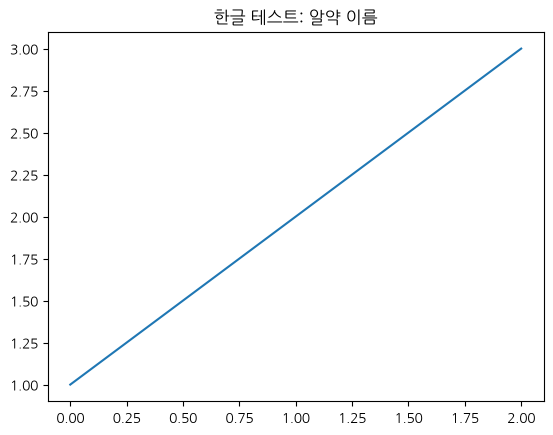

In [ ]:
# 한글 폰트 깨짐
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import font_manager

current_dir = Path.cwd()
font_path = next(
    (
        folder / "notebooks/fonts/NanumGothic.ttf"
        for folder in [current_dir, *current_dir.parents]
        if (folder / "notebooks/fonts/NanumGothic.ttf").is_file()
    ),
    None,
)

if font_path is None:
    raise FileNotFoundError("노트북 실행 환경에서 폰트 파일을 찾지 못했어요.")

font_manager.fontManager.addfont(str(font_path))
plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(font_path)).get_name()
plt.rcParams["axes.unicode_minus"] = False

plt.figure()
plt.title("한글 테스트: 알약 이름")
plt.plot([1, 2, 3])
plt.show()

In [ ]:
from pathlib import Path

# 노트북을 실행한 위치가 프로젝트 루트인지 notebooks 폴더인지 확인
current_dir = Path.cwd()
project_root = current_dir if (current_dir / "pyproject.toml").exists() else current_dir.parent

data_dir = project_root / "data" / "raw"

print("데이터 경로:", data_dir)
print("폴더 존재 여부:", data_dir.is_dir())

데이터 경로: /home/edith/pill-bbox/data/raw
폴더 존재 여부: True


In [ ]:
train_image_dir = data_dir / "train_images"
test_image_dir = data_dir / "test_images"
annotation_dir = data_dir / "train_annotations"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# 하위 폴더까지 탐색해서 이미지 파일만 모으기
train_image_files = [
    path
    for path in train_image_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

test_image_files = [
    path
    for path in test_image_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

json_files = [
    path for path in annotation_dir.rglob("*") if path.is_file() and path.suffix.lower() == ".json"
]

print(f"학습 이미지 수: {len(train_image_files):,}개")
print(f"테스트 이미지 수: {len(test_image_files):,}개")
print(f"전체 이미지 수: {len(train_image_files) + len(test_image_files):,}개")
print(f"학습 JSON 파일 수: {len(json_files):,}개")

학습 이미지 수: 232개
테스트 이미지 수: 842개
전체 이미지 수: 1,074개
학습 JSON 파일 수: 763개


In [ ]:
import json

import pandas as pd

with json_files[0].open(encoding="utf-8") as file:
    data = json.load(file)

# 열이 생략되지 않도록 설정
pd.set_option("display.max_columns", None)

# 이미지·알약 정보를 표로 변환
df = pd.json_normalize(data["images"])

df.head()

,file_name,width,height,imgfile,drug_N,drug_S,back_color,drug_dir,light_color,camera_la,camera_lo,size,dl_idx,dl_mapping_code,dl_name,dl_name_en,img_key,dl_material,dl_material_en,dl_custom_shape,dl_company,dl_company_en,di_company_mf,di_company_mf_en,item_seq,di_item_permit_date,di_class_no,di_etc_otc_code,di_edi_code,chart,drug_shape,thick,leng_long,leng_short,print_front,print_back,color_class1,color_class2,line_front,line_back,img_regist_ts,form_code_name,mark_code_front_anal,mark_code_back_anal,mark_code_front_img,mark_code_back_img,mark_code_front,mark_code_back,change_date,id
0,K-003351-021325-032310_0_2_0_2_75_000_200.png,976,1280,K-003351-021325-032310_0_2_0_2_75_000_200.png,K-032310,정상알약,연회색 배경,앞면,주백색,75,0,200,32310,K-032310,글리아타민연질캡슐,,http://connectdi.com/design/img/drug/154039561...,콜린알포세레이트,Choline alfoscerate,연질캡슐제,대웅바이오(주),Daewoong Bio,"(주)서흥, (주)알피바이오, 코스맥스파마(주)","Suheung, Rp Bio, Cosmax Pharma",201310719,20131217,[01190]기타의 중추신경용약,전문의약품,694000600,무색투명의 점조한 액을 넣은 담황색을 띤 타원형의 연질캡슐제,타원형,8.5,15.5,8.5,글리아타민,,갈색,,,,20151001,"연질캡슐제, 액상",,,,,,,20210728,1382


In [5]:
df.head(5).T

,0
file_name,K-003351-021325-032310_0_2_0_2_75_000_200.png
width,976
height,1280
imgfile,K-003351-021325-032310_0_2_0_2_75_000_200.png
drug_N,K-032310
drug_S,정상알약
back_color,연회색 배경
drug_dir,앞면
light_color,주백색
camera_la,75


In [6]:
image_records = []

for json_path in json_files[:5]:
    with json_path.open(encoding="utf-8") as file:
        data = json.load(file)

    image_records.extend(data["images"])

df = pd.json_normalize(image_records)

df.head().T

,0,1,2,3,4
file_name,K-003351-021325-032310_0_2_0_2_75_000_200.png,K-003351-021325-032310_0_2_0_2_75_000_200.png,K-003351-021325-032310_0_2_0_2_90_000_200.png,K-003351-021325-032310_0_2_0_2_75_000_200.png,K-003351-021325-032310_0_2_0_2_90_000_200.png
width,976,976,976,976,976
height,1280,1280,1280,1280,1280
imgfile,K-003351-021325-032310_0_2_0_2_75_000_200.png,K-003351-021325-032310_0_2_0_2_75_000_200.png,K-003351-021325-032310_0_2_0_2_90_000_200.png,K-003351-021325-032310_0_2_0_2_75_000_200.png,K-003351-021325-032310_0_2_0_2_90_000_200.png
drug_N,K-032310,K-003351,K-003351,K-021325,K-021325
drug_S,정상알약,정상알약,정상알약,정상알약,정상알약
back_color,연회색 배경,연회색 배경,연회색 배경,연회색 배경,연회색 배경
drug_dir,앞면,앞면,앞면,앞면,앞면
light_color,주백색,주백색,주백색,주백색,주백색
camera_la,75,75,90,75,90


In [ ]:
# 전체 JSON 파일 목록을 다시 만들기
json_files = [
    path for path in annotation_dir.rglob("*") if path.is_file() and path.suffix.lower() == ".json"
]

image_records = []

for json_path in json_files:
    with json_path.open(encoding="utf-8") as file:
        data = json.load(file)

    image_records.extend(data["images"])

df = pd.json_normalize(image_records)

print("읽은 JSON 파일 수:", len(json_files))
print("만들어진 데이터 행 수:", len(df))

display(df.shape)
display(df.columns)
display(df.info())
display(df.describe().round(2))

읽은 JSON 파일 수: 763
만들어진 데이터 행 수: 763


(763, 50)

Index(['file_name', 'width', 'height', 'imgfile', 'drug_N', 'drug_S',
       'back_color', 'drug_dir', 'light_color', 'camera_la', 'camera_lo',
       'size', 'dl_idx', 'dl_mapping_code', 'dl_name', 'dl_name_en', 'img_key',
       'dl_material', 'dl_material_en', 'dl_custom_shape', 'dl_company',
       'dl_company_en', 'di_company_mf', 'di_company_mf_en', 'item_seq',
       'di_item_permit_date', 'di_class_no', 'di_etc_otc_code', 'di_edi_code',
       'chart', 'drug_shape', 'thick', 'leng_long', 'leng_short',
       'print_front', 'print_back', 'color_class1', 'color_class2',
       'line_front', 'line_back', 'img_regist_ts', 'form_code_name',
       'mark_code_front_anal', 'mark_code_back_anal', 'mark_code_front_img',
       'mark_code_back_img', 'mark_code_front', 'mark_code_back',
       'change_date', 'id'],
      dtype='str')

<class 'pandas.DataFrame'>
RangeIndex: 763 entries, 0 to 762
Data columns (total 50 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   file_name             763 non-null    str    
 1   width                 763 non-null    int64  
 2   height                763 non-null    int64  
 3   imgfile               763 non-null    str    
 4   drug_N                763 non-null    str    
 5   drug_S                763 non-null    str    
 6   back_color            763 non-null    str    
 7   drug_dir              763 non-null    str    
 8   light_color           763 non-null    str    
 9   camera_la             763 non-null    int64  
 10  camera_lo             763 non-null    int64  
 11  size                  763 non-null    int64  
 12  dl_idx                763 non-null    str    
 13  dl_mapping_code       763 non-null    str    
 14  dl_name               763 non-null    str    
 15  dl_name_en            763 non-null

None

,width,height,camera_la,camera_lo,size,item_seq,thick,leng_long,leng_short,id
count,763.0,763.0,763.00,763.0,763.0,7.630000e+02,763.00,763.00,763.00,763.00
mean,976.0,1280.0,78.89,0.0,200.0,2.002988e+08,4.58,11.37,7.23,756.20
std,0.0,0.0,8.63,0.0,0.0,9.347887e+05,1.93,4.75,1.92,448.18
min,976.0,1280.0,70.00,0.0,200.0,1.987007e+08,0.00,0.00,0.00,14.00
25%,976.0,1280.0,70.00,0.0,200.0,1.991020e+08,2.76,7.24,6.10,369.00
50%,976.0,1280.0,75.00,0.0,200.0,2.006000e+08,4.00,11.00,7.01,792.00
75%,976.0,1280.0,90.00,0.0,200.0,2.010077e+08,6.00,15.50,8.50,1160.00
max,976.0,1280.0,90.00,0.0,200.0,2.017027e+08,9.80,24.00,12.58,1499.00


In [8]:
display("tail")
display(df.tail())
display("sample")
display(df.sample(5))
display("열별 결측치 개수 확인")
display(df.isna().sum())

'tail'

,file_name,width,height,imgfile,drug_N,drug_S,back_color,drug_dir,light_color,camera_la,camera_lo,size,dl_idx,dl_mapping_code,dl_name,dl_name_en,img_key,dl_material,dl_material_en,dl_custom_shape,dl_company,dl_company_en,di_company_mf,di_company_mf_en,item_seq,di_item_permit_date,di_class_no,di_etc_otc_code,di_edi_code,chart,drug_shape,thick,leng_long,leng_short,print_front,print_back,color_class1,color_class2,line_front,line_back,img_regist_ts,form_code_name,mark_code_front_anal,mark_code_back_anal,mark_code_front_img,mark_code_back_img,mark_code_front,mark_code_back,change_date,id
758,K-002483-012081-012778-025438_0_2_0_2_70_000_2...,976,1280,K-002483-012081-012778-025438_0_2_0_2_70_000_2...,K-012081,정상알약,연회색 배경,앞면,주백색,70,0,200,12081,K-012081,리렉스펜정 300mg/PTP,Lirexpen Tab.,http://connectdi.com/design/img/drug/1MdYV-PxY...,아세트아미노펜|클로르족사존,Acetaminophen| Chlorzoxazone,"정제, 저작정",한미약품(주),Hanmi Pharm,에이치엘비제약(주),Hlb Pharma,200202194,20020730,[01140]해열.진통.소염제,일반의약품,643500690,흰색의 장방형 정제,장방형,4.9,17.6,8.1,HMP,RP,하양,,,,20190328,나정,,,,,,,20181217,794
759,K-002483-012081-012778-025438_0_2_0_2_90_000_2...,976,1280,K-002483-012081-012778-025438_0_2_0_2_90_000_2...,K-012081,정상알약,연회색 배경,앞면,주백색,90,0,200,12081,K-012081,리렉스펜정 300mg/PTP,Lirexpen Tab.,http://connectdi.com/design/img/drug/1MdYV-PxY...,아세트아미노펜|클로르족사존,Acetaminophen| Chlorzoxazone,"정제, 저작정",한미약품(주),Hanmi Pharm,에이치엘비제약(주),Hlb Pharma,200202194,20020730,[01140]해열.진통.소염제,일반의약품,643500690,흰색의 장방형 정제,장방형,4.9,17.6,8.1,HMP,RP,하양,,,,20190328,나정,,,,,,,20181217,795
760,K-002483-012081-012778-025438_0_2_0_2_75_000_2...,976,1280,K-002483-012081-012778-025438_0_2_0_2_75_000_2...,K-025438,정상알약,연회색 배경,앞면,주백색,75,0,200,25438,K-025438,큐시드정 31.5mg/PTP,Q-Cid Tab.,http://connectdi.com/design/img/drug/147426411...,라니티딘염산염|산화마그네슘|규산알루민산마그네슘|수산화알루민산마그네슘,Aluminum Magnesium Hydroxide| Aluminum Magnesi...,"정제, 저작정",(주)유한양행,Yuhan,,,200902214,20090326,[02340]제산제,일반의약품,642104830,연녹색의 원형 필름코팅정제,원형,5.1,10.1,10.1,Q,YH,연두,,,,20160329,필름코팅정,,,,,,,20190916,793
761,K-002483-012081-012778-025438_0_2_0_2_70_000_2...,976,1280,K-002483-012081-012778-025438_0_2_0_2_70_000_2...,K-025438,정상알약,연회색 배경,앞면,주백색,70,0,200,25438,K-025438,큐시드정 31.5mg/PTP,Q-Cid Tab.,http://connectdi.com/design/img/drug/147426411...,라니티딘염산염|산화마그네슘|규산알루민산마그네슘|수산화알루민산마그네슘,Aluminum Magnesium Hydroxide| Aluminum Magnesi...,"정제, 저작정",(주)유한양행,Yuhan,,,200902214,20090326,[02340]제산제,일반의약품,642104830,연녹색의 원형 필름코팅정제,원형,5.1,10.1,10.1,Q,YH,연두,,,,20160329,필름코팅정,,,,,,,20190916,794
762,K-002483-012081-012778-025438_0_2_0_2_90_000_2...,976,1280,K-002483-012081-012778-025438_0_2_0_2_90_000_2...,K-025438,정상알약,연회색 배경,앞면,주백색,90,0,200,25438,K-025438,큐시드정 31.5mg/PTP,Q-Cid Tab.,http://connectdi.com/design/img/drug/147426411...,라니티딘염산염|산화마그네슘|규산알루민산마그네슘|수산화알루민산마그네슘,Aluminum Magnesium Hydroxide| Aluminum Magnesi...,"정제, 저작정",(주)유한양행,Yuhan,,,200902214,20090326,[02340]제산제,일반의약품,642104830,연녹색의 원형 필름코팅정제,원형,5.1,10.1,10.1,Q,YH,연두,,,,20160329,필름코팅정,,,,,,,20190916,795


'sample'

,file_name,width,height,imgfile,drug_N,drug_S,back_color,drug_dir,light_color,camera_la,camera_lo,size,dl_idx,dl_mapping_code,dl_name,dl_name_en,img_key,dl_material,dl_material_en,dl_custom_shape,dl_company,dl_company_en,di_company_mf,di_company_mf_en,item_seq,di_item_permit_date,di_class_no,di_etc_otc_code,di_edi_code,chart,drug_shape,thick,leng_long,leng_short,print_front,print_back,color_class1,color_class2,line_front,line_back,img_regist_ts,form_code_name,mark_code_front_anal,mark_code_back_anal,mark_code_front_img,mark_code_back_img,mark_code_front,mark_code_back,change_date,id
114,K-003483-016262-019861-028763_0_2_0_2_70_000_2...,976,1280,K-003483-016262-019861-028763_0_2_0_2_70_000_2...,K-016262,정상알약,연회색 배경,앞면,주백색,70,0,200,16262,K-016262,크레스토정 20mg,Crestor Tab. 20mg,http://connectdi.com/design/img/drug/151317963...,로수바스타틴칼슘,Rosuvastatin Calcium,"정제, 저작정",한국아스트라제네카(주),Astrazeneca Korea,,,200410326,20040831,[02180]동맥경화용제,전문의약품,"650700530,E06610651",분홍색 원형 필름코팅정,원형,4.5,9.2,9.2,ZD452220,,분홍,,,,20041222,필름코팅정,,,,,,,20201119,441
683,K-003483-020877-025367-035206_0_2_0_2_70_000_2...,976,1280,K-003483-020877-025367-035206_0_2_0_2_70_000_2...,K-035206,정상알약,연회색 배경,앞면,주백색,70,0,200,35206,K-035206,아토젯정 10/40mg,Atozet Tab. 10/40mg,http://connectdi.com/design/img/drug/1NVzhGcz6...,에제티미브|아토르바스타틴칼슘삼수화물,Atorvastatin Calcium Trihydrate| Ezetimibe,"정제, 저작정",한국엠에스디(주),Msd Korea,,,201500365,20150123,[02180]동맥경화용제,전문의약품,655501870,백색 내지 미백색의 한 면에 337이 새겨진 양면이 볼록한 캡슐모양의 필름코팅정,타원형,7.0,17.0,7.0,337,,하양,,,,20150226,필름코팅정,,,,,,,20190805,1320
247,K-003544-004543-016548-027993_0_2_0_2_75_000_2...,976,1280,K-003544-004543-016548-027993_0_2_0_2_75_000_2...,K-016548,정상알약,연회색 배경,앞면,주백색,75,0,200,16548,K-016548,가바토파정 100mg,Gabatopa Tab. 100mg,NaN,토피라메이트,Topiramate,"정제, 저작정",동아에스티(주),Dong-A St,,,200500251,20050628,[01130]항전간제,전문의약품,"642500020,A01508461",NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1134
743,K-003351-018357-020238_0_2_0_2_70_000_200.png,976,1280,K-003351-018357-020238_0_2_0_2_70_000_200.png,K-020238,정상알약,연회색 배경,앞면,주백색,70,0,200,20238,K-020238,플라빅스정 75mg,Plavix Tab. 75mg,http://connectdi.com/design/img/drug/149883724...,클로피도그렐황산염,Clopidogrel Bisulfate,"정제, 저작정",(주)한독,Handok,Sanofi Winthrop Industrie,,200700907,20070122,[02180]동맥경화용제,전문의약품,"652101570,A07404851",분홍색의 원형필름코팅정,원형,4.0,8.5,8.5,75,1171,분홍,,,,20041222,필름코팅정,,,,,,,20210426,1324
724,K-003351-016262-031863_0_2_0_2_70_000_200.png,976,1280,K-003351-016262-031863_0_2_0_2_70_000_200.png,K-031863,정상알약,연회색 배경,앞면,주백색,70,0,200,31863,K-031863,아질렉트정(라사길린메실산염),Azilect Tab.,http://connectdi.com/design/img/drug/147426780...,라사길린메실산염,Rasagiline Mesylate,"정제, 저작정",한국룬드벡(주),Lundbeck Korea,Teva Pharmaceutical Industries Ltd.,,201309347,20130913,[01190]기타의 중추신경용약,전문의약품,668000100,"한쪽 면의 위쪽에 “GIL"", 아래쪽에 ”1“이 새겨진 흰색 또는 거의 흰색의 모서...",원형,3.0,8.0,8.0,GIL 1,,하양,,,,20131224,나정,,,,,,,20210106,856


'열별 결측치 개수 확인'

file_name                0
width                    0
height                   0
imgfile                  0
drug_N                   0
drug_S                   0
back_color               0
drug_dir                 0
light_color              0
camera_la                0
camera_lo                0
size                     0
dl_idx                   0
dl_mapping_code          0
dl_name                  0
dl_name_en               0
img_key                 18
dl_material              0
dl_material_en           0
dl_custom_shape          0
dl_company               0
dl_company_en            0
di_company_mf            0
di_company_mf_en         0
item_seq                 0
di_item_permit_date      0
di_class_no              0
di_etc_otc_code          0
di_edi_code              0
chart                   18
drug_shape              18
thick                    0
leng_long                0
leng_short               0
print_front             18
print_back              18
color_class1            18
c

In [9]:
display("df에서 결측치가 1개 이상 있는 열을 조회")
missing_counts = df.isna().sum()
missing_counts[missing_counts > 0].sort_values(ascending=False)
display(missing_counts[missing_counts > 0].index.tolist())

# display("서로 다른 값이 몇 개인지 확인")
# display(df["열이름"].unique(()))

'df에서 결측치가 1개 이상 있는 열을 조회'

['img_key',
 'chart',
 'drug_shape',
 'print_front',
 'print_back',
 'color_class1',
 'color_class2',
 'line_front',
 'line_back',
 'img_regist_ts',
 'form_code_name',
 'mark_code_front_anal',
 'mark_code_back_anal',
 'mark_code_front_img',
 'mark_code_back_img',
 'mark_code_front',
 'mark_code_back',
 'change_date']

In [10]:
# 빈 문자열과 공백만 있는 문자열을 결측치로 바꾼 표
df_missing = df.replace(r"^\s*$", pd.NA, regex=True)

# 결측치가 있는 열만 개수 출력
missing_counts = df_missing.isna().sum()
missing_counts[missing_counts > 0].sort_values(ascending=False)

mark_code_front         763
mark_code_back_img      763
mark_code_back_anal     763
mark_code_back          763
di_company_mf_en        724
color_class2            711
mark_code_front_img     660
mark_code_front_anal    660
line_back               648
di_company_mf           637
line_front              570
print_back              274
print_front              34
chart                    18
img_regist_ts            18
color_class1             18
img_key                  18
drug_shape               18
form_code_name           18
change_date              18
dl_name_en               14
dl_material               9
dtype: int64

빈 문자열과 공백은 '정보가 없음'인지 '원래 해당 사항이 없음'인지  
표본이 많지 않기 때문에 **결측치가 많다고 삭제하기보다, 어떤 정보가 왜 비었는지 구분해서 기록할 필요가 있다**  
| 항목 | 비어 있는 이유로 생각해 볼 수 있는 것 |
|---|---|
| `print_front`, `print_back` | 해당 면에 식별문자가 없을 수 있음 |
| `line_front`, `line_back` | 분할선이 없을 수 있음 |
| `color_class2` | 두 번째 색상이 없는 단색 알약일 수 있음 |
| `mark_code_*` | 마크가 없거나 마크 정보가 수집되지 않았을 수 있음 |
| `di_company_mf_en` | 위탁제조사 영문명이 제공되지 않았을 수 있음 |  
이건 가능한 해석이야. 빈 값만 보고 ‘마크 없음’이나 ‘분할선 없음’으로 확정하면 안 돼. 데이터 설명과 실제 이미지를 같이 확인해야 해.

In [ ]:
# chart, color_class1, drug_shape 등에서 똑같이 18개씩 비어 있는 행들을 뽑아봄
columns_to_check = [
    "file_name",
    "dl_idx",
    "dl_name",
    "chart",
    "color_class1",
    "drug_shape",
    "form_code_name",
]

df_missing.loc[
    df_missing["chart"].isna(),
    columns_to_check,
]

,file_name,dl_idx,dl_name,chart,color_class1,drug_shape,form_code_name
245,K-003544-004543-016548-027993_0_2_0_2_90_000_2...,16548,가바토파정 100mg,NaN,NaN,NaN,NaN
246,K-003544-004543-016548-027993_0_2_0_2_70_000_2...,16548,가바토파정 100mg,NaN,NaN,NaN,NaN
247,K-003544-004543-016548-027993_0_2_0_2_75_000_2...,16548,가바토파정 100mg,NaN,NaN,NaN,NaN
347,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,16548,가바토파정 100mg,NaN,NaN,NaN,NaN
348,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,16548,가바토파정 100mg,NaN,NaN,NaN,NaN
349,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,16548,가바토파정 100mg,NaN,NaN,NaN,NaN
509,K-003544-004543-012247-016548_0_2_0_2_90_000_2...,16548,가바토파정 100mg,NaN,NaN,NaN,NaN
510,K-003544-004543-012247-016548_0_2_0_2_70_000_2...,16548,가바토파정 100mg,NaN,NaN,NaN,NaN
511,K-003544-004543-012247-016548_0_2_0_2_75_000_2...,16548,가바토파정 100mg,NaN,NaN,NaN,NaN
593,K-001900-016548-021771-027926_0_2_0_2_75_000_2...,16548,가바토파정 100mg,NaN,NaN,NaN,NaN


대상 이미지: 18개
저장 폴더: /home/edith/pill-bbox/notebooks/eda_missing_images


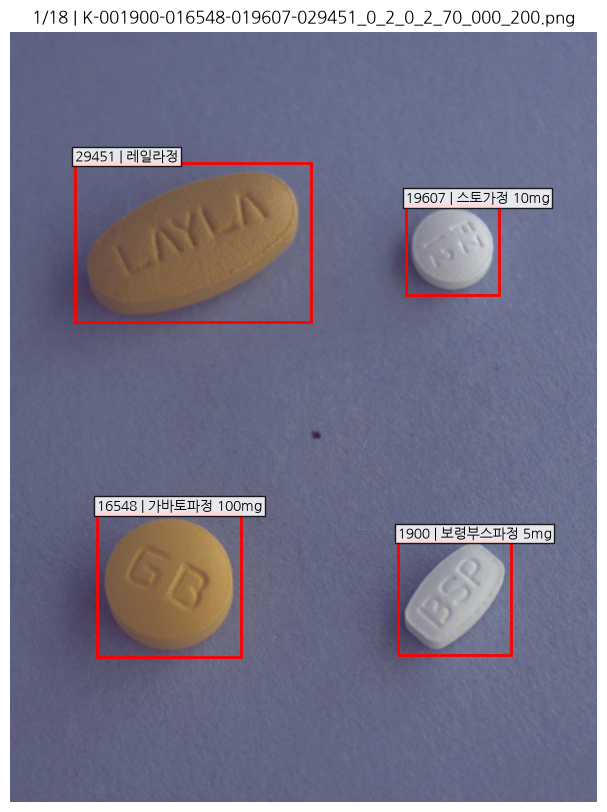

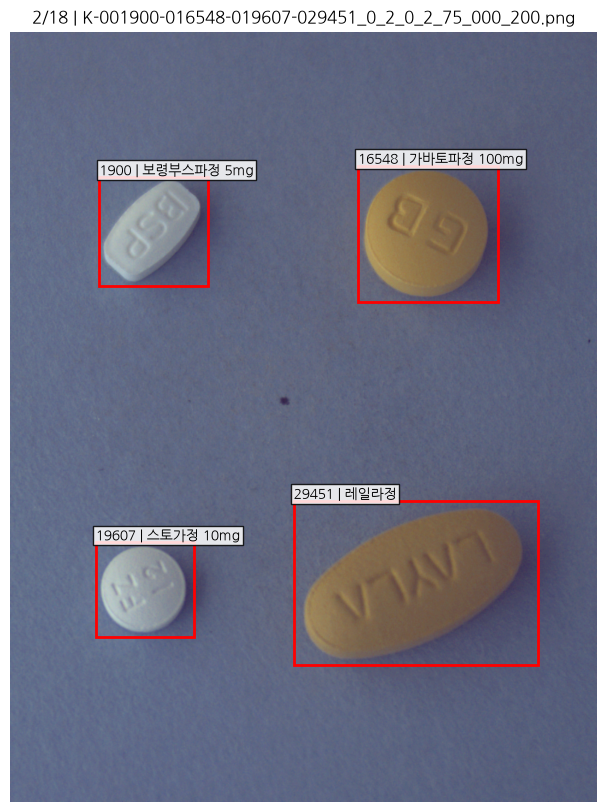

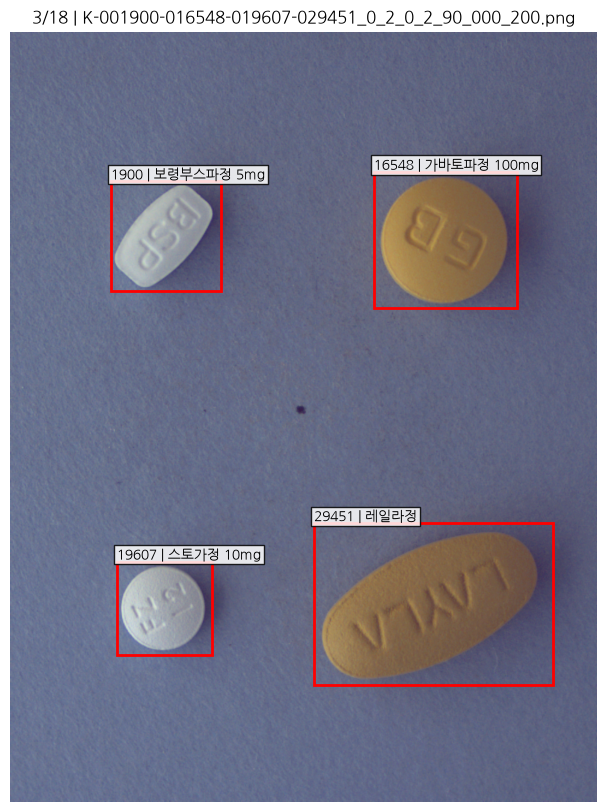

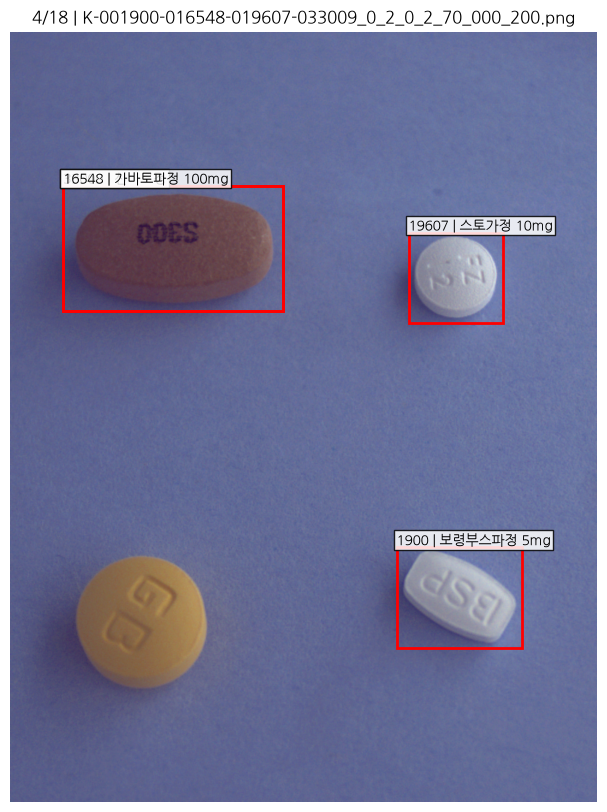

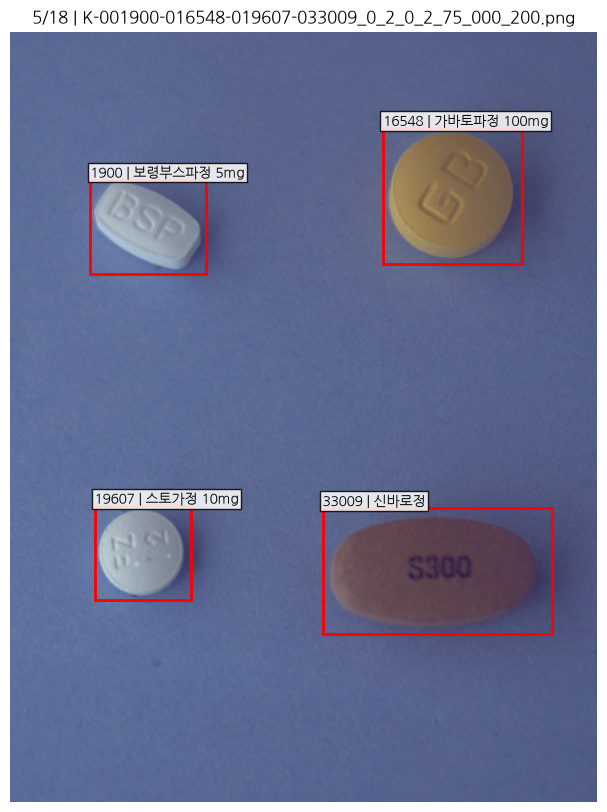

...

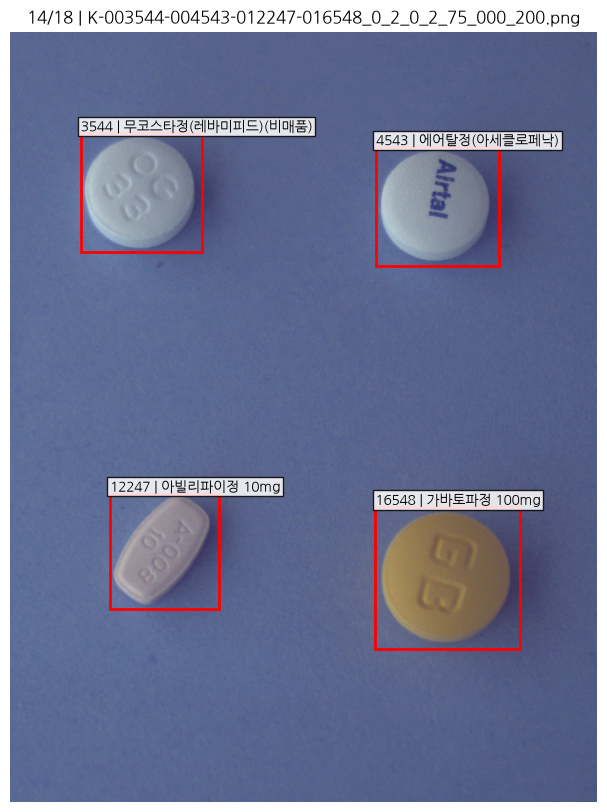

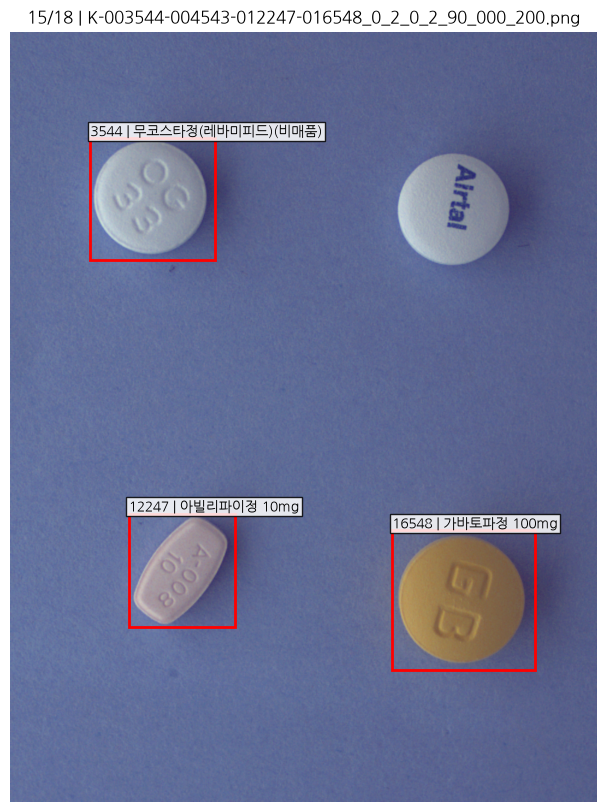

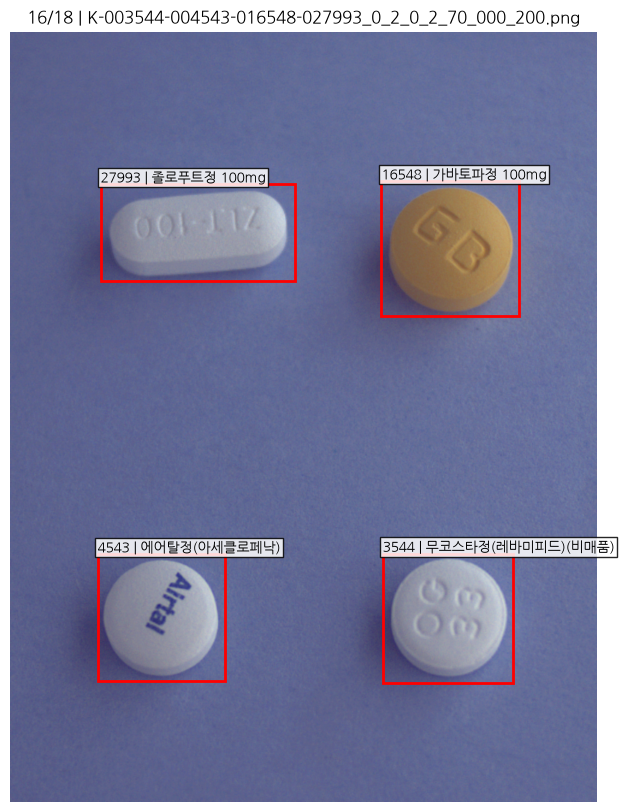

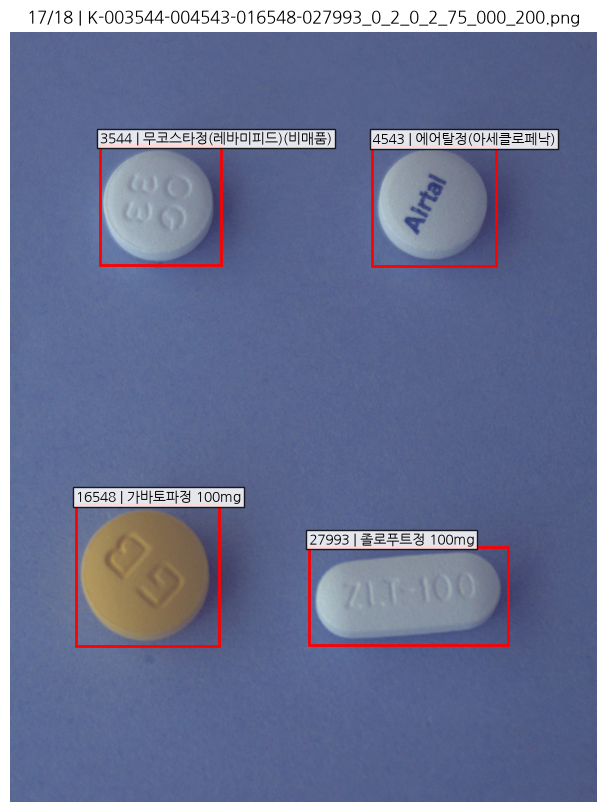

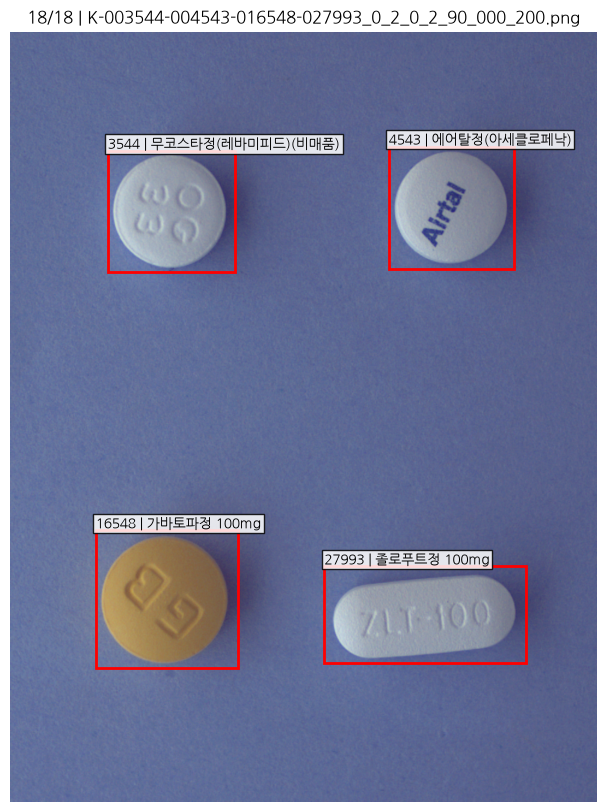

In [ ]:
import json

import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib import font_manager
from PIL import Image

# 설치된 한글 폰트 사용
font_candidates = ["NanumGothic", "Noto Sans CJK KR", "Malgun Gothic", "AppleGothic"]
installed_fonts = {font.name for font in font_manager.fontManager.ttflist}

for font_name in font_candidates:
    if font_name in installed_fonts:
        plt.rcParams["font.family"] = font_name
        break
else:
    print("한글 폰트가 없어 알약 이름이 네모로 보일 수 있어요.")

plt.rcParams["axes.unicode_minus"] = False

# 확인할 대상: chart가 비어 있는 행
target_rows = df_missing.loc[df_missing["chart"].isna()]
target_names = set(target_rows["file_name"].dropna().map(lambda x: Path(x).name))

# 이미지 이름으로 실제 경로 찾기
image_paths = {}
for image_path in train_image_files:
    image_paths.setdefault(image_path.name, []).append(image_path)

# 선택된 이미지에 해당하는 어노테이션 모으기
image_records = {}

for json_path in json_files:
    with json_path.open(encoding="utf-8") as file:
        annotation_data = json.load(file)

    categories = {
        category["id"]: category.get("name", "") for category in annotation_data["categories"]
    }

    for image_info in annotation_data["images"]:
        file_name = Path(image_info["file_name"]).name

        if file_name not in target_names:
            continue

        record = image_records.setdefault(file_name, [])

        for annotation in annotation_data["annotations"]:
            if annotation["image_id"] != image_info["id"]:
                continue

            class_id = annotation["category_id"]
            pill_name = categories.get(class_id) or image_info.get("dl_name", "이름 없음")

            record.append(
                {
                    "bbox": annotation["bbox"],
                    "class_id": class_id,
                    "pill_name": pill_name,
                }
            )

output_dir = project_root / "notebooks" / "eda_missing_images"
output_dir.mkdir(parents=True, exist_ok=True)

print(f"대상 이미지: {len(target_names)}개")
print(f"저장 폴더: {output_dir}")

for index, file_name in enumerate(sorted(target_names), start=1):
    paths = image_paths.get(file_name, [])

    if len(paths) != 1:
        print(f"건너뜀: {file_name} — 같은 이름의 이미지 경로가 {len(paths)}개")
        continue

    with Image.open(paths[0]) as image:
        image = image.convert("RGB")

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(image)

    # 여러 JSON에 같은 박스가 있으면 한 번만 표시
    drawn_boxes = set()

    for record in image_records.get(file_name, []):
        bbox = record["bbox"]
        box_key = (tuple(bbox), record["class_id"])

        if box_key in drawn_boxes:
            continue
        drawn_boxes.add(box_key)

        # 데이터의 bbox 형식: [왼쪽 x, 위쪽 y, 너비, 높이]
        x, y, width, height = bbox

        ax.add_patch(
            plt.Rectangle(
                (x, y),
                width,
                height,
                fill=False,
                edgecolor="red",
                linewidth=2,
            )
        )
        ax.text(
            x,
            y,
            f"{record['class_id']} | {record['pill_name']}",
            color="black",
            fontsize=10,
            va="bottom",
            bbox={"facecolor": "white", "alpha": 0.85, "pad": 2},
        )

    ax.set_title(f"{index}/{len(target_names)} | {file_name}")
    ax.axis("off")

    output_path = output_dir / f"{index:04d}_{Path(file_name).stem}.png"
    fig.savefig(output_path, bbox_inches="tight", dpi=150)
    display(fig)
    plt.close(fig)

지금 확인한 결측치는 대부분 사진의 문제가 아니라, JSON에 적힌 설명 정보가 비어 있는 문제라서 사진만으로는 구분하기 어려워.
예를 들어:
- dl_company_en이 비어 있음 → 제조사 영문명이 없다는 뜻이라 사진으로 확인할 수 없어.
- print_back이 비어 있음 → 실제로 뒷면 문자가 없는지, 정보를 빠뜨렸는지 사진과 비교할 수 있어.
- chart가 비어 있음 → 알약의 외형 설명 문장이 없는 것이지, 사진이나 bbox가 없다는 뜻은 아니야.
그래서 이미지 옆에 “이 행에서 비어 있는 열 목록”을 같이 봐야 해. 우선 표로 확인해 봐.

In [13]:
# 각 행에서 비어 있는 열 이름을 모으기
missing_columns = df_missing.isna().apply(
    lambda row: row.index[row].tolist(),
    axis=1,
)

# 이미지·알약 정보 옆에 결측 항목 표시
review_df = df_missing[["file_name", "dl_idx", "dl_name"]].copy()
review_df["결측 항목"] = missing_columns

# 앞에서 이미지로 확인했던 chart 결측 행
pd.set_option("display.max_colwidth", None)

display(review_df.loc[df_missing["chart"].isna()])

,file_name,dl_idx,dl_name,결측 항목
245,K-003544-004543-016548-027993_0_2_0_2_90_000_200.png,16548,가바토파정 100mg,"[img_key, di_company_mf, di_company_mf_en, chart, drug_shape, print_front, print_back, color_class1, color_class2, line_front, line_back, img_regist_ts, form_code_name, mark_code_front_anal, mark_code_back_anal, mark_code_front_img, mark_code_back_img, mark_code_front, mark_code_back, change_date]"
246,K-003544-004543-016548-027993_0_2_0_2_70_000_200.png,16548,가바토파정 100mg,"[img_key, di_company_mf, di_company_mf_en, chart, drug_shape, print_front, print_back, color_class1, color_class2, line_front, line_back, img_regist_ts, form_code_name, mark_code_front_anal, mark_code_back_anal, mark_code_front_img, mark_code_back_img, mark_code_front, mark_code_back, change_date]"
247,K-003544-004543-016548-027993_0_2_0_2_75_000_200.png,16548,가바토파정 100mg,"[img_key, di_company_mf, di_company_mf_en, chart, drug_shape, print_front, print_back, color_class1, color_class2, line_front, line_back, img_regist_ts, form_code_name, mark_code_front_anal, mark_code_back_anal, mark_code_front_img, mark_code_back_img, mark_code_front, mark_code_back, change_date]"
347,K-001900-016548-019607-029451_0_2_0_2_90_000_200.png,16548,가바토파정 100mg,"[img_key, di_company_mf, di_company_mf_en, chart, drug_shape, print_front, print_back, color_class1, color_class2, line_front, line_back, img_regist_ts, form_code_name, mark_code_front_anal, mark_code_back_anal, mark_code_front_img, mark_code_back_img, mark_code_front, mark_code_back, change_date]"
348,K-001900-016548-019607-029451_0_2_0_2_75_000_200.png,16548,가바토파정 100mg,"[img_key, di_company_mf, di_company_mf_en, chart, drug_shape, print_front, print_back, color_class1, color_class2, line_front, line_back, img_regist_ts, form_code_name, mark_code_front_anal, mark_code_back_anal, mark_code_front_img, mark_code_back_img, mark_code_front, mark_code_back, change_date]"
349,K-001900-016548-019607-029451_0_2_0_2_70_000_200.png,16548,가바토파정 100mg,"[img_key, di_company_mf, di_company_mf_en, chart, drug_shape, print_front, print_back, color_class1, color_class2, line_front, line_back, img_regist_ts, form_code_name, mark_code_front_anal, mark_code_back_anal, mark_code_front_img, mark_code_back_img, mark_code_front, mark_code_back, change_date]"
509,K-003544-004543-012247-016548_0_2_0_2_90_000_200.png,16548,가바토파정 100mg,"[img_key, di_company_mf, di_company_mf_en, chart, drug_shape, print_front, print_back, color_class1, color_class2, line_front, line_back, img_regist_ts, form_code_name, mark_code_front_anal, mark_code_back_anal, mark_code_front_img, mark_code_back_img, mark_code_front, mark_code_back, change_date]"
510,K-003544-004543-012247-016548_0_2_0_2_70_000_200.png,16548,가바토파정 100mg,"[img_key, di_company_mf, di_company_mf_en, chart, drug_shape, print_front, print_back, color_class1, color_class2, line_front, line_back, img_regist_ts, form_code_name, mark_code_front_anal, mark_code_back_anal, mark_code_front_img, mark_code_back_img, mark_code_front, mark_code_back, change_date]"
511,K-003544-004543-012247-016548_0_2_0_2_75_000_200.png,16548,가바토파정 100mg,"[img_key, di_company_mf, di_company_mf_en, chart, drug_shape, print_front, print_back, color_class1, color_class2, line_front, line_back, img_regist_ts, form_code_name, mark_code_front_anal, mark_code_back_anal, mark_code_front_img, mark_code_back_img, mark_code_front, mark_code_back, change_date]"
593,K-001900-016548-021771-027926_0_2_0_2_75_000_200.png,16548,가바토파정 100mg,"[img_key, di_company_mf, di_company_mf_en, chart, drug_shape, print_front, print_back, color_class1, color_class2, line_front, line_back, img_regist_ts, form_code_name, mark_code_front_anal, mark_code_back_anal, mark_code_front_img, mark_code_back_img, mark_code_front, mark_code_back, change_date]"


## 이상치
1. 좌표 오류
2. 면적 비율 이상치 후보
3. 가로세로 비율 이상치 후보

In [ ]:
# 1. bbox 정보 모으기
bbox_records = []

for json_path in json_files:
    with json_path.open(encoding="utf-8") as file:
        data = json.load(file)

    images_by_id = {image["id"]: image for image in data["images"]}
    names_by_id = {category["id"]: category.get("name") for category in data["categories"]}

    for annotation in data["annotations"]:
        image = images_by_id.get(annotation["image_id"])

        if image is None:
            continue

        x, y, width, height = annotation["bbox"]

        bbox_records.append(
            {
                "json_path": str(json_path),
                "file_name": image["file_name"],
                "class_id": annotation["category_id"],
                "pill_name": names_by_id.get(annotation["category_id"]),
                "image_width": image["width"],
                "image_height": image["height"],
                "x": x,
                "y": y,
                "width": width,
                "height": height,
            }
        )

bbox_df = pd.DataFrame(bbox_records)
bbox_df.head()

,json_path,file_name,class_id,pill_name,image_width,image_height,x,y,width,height
0,/home/edith/pill-bbox/data/raw/train_annotations/K-003351-021325-032310_json/K-032310/K-003351-021325-032310_0_2_0_2_75_000_200.json,K-003351-021325-032310_0_2_0_2_75_000_200.png,32310,글리아타민연질캡슐,976,1280,540,718,383,246
1,/home/edith/pill-bbox/data/raw/train_annotations/K-003351-021325-032310_json/K-003351/K-003351-021325-032310_0_2_0_2_75_000_200.json,K-003351-021325-032310_0_2_0_2_75_000_200.png,3351,일양하이트린정 2mg,976,1280,343,182,180,187
2,/home/edith/pill-bbox/data/raw/train_annotations/K-003351-021325-032310_json/K-003351/K-003351-021325-032310_0_2_0_2_90_000_200.json,K-003351-021325-032310_0_2_0_2_90_000_200.png,3351,일양하이트린정 2mg,976,1280,382,242,185,183
3,/home/edith/pill-bbox/data/raw/train_annotations/K-003351-021325-032310_json/K-021325/K-003351-021325-032310_0_2_0_2_75_000_200.json,K-003351-021325-032310_0_2_0_2_75_000_200.png,21325,아토르바정 10mg,976,1280,48,808,251,146
4,/home/edith/pill-bbox/data/raw/train_annotations/K-003351-021325-032310_json/K-021325/K-003351-021325-032310_0_2_0_2_90_000_200.json,K-003351-021325-032310_0_2_0_2_90_000_200.png,21325,아토르바정 10mg,976,1280,91,893,245,143


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

# 이미지 파일 이름과 실제 경로 연결
image_paths = {}

for image_path in train_image_files:
    image_paths.setdefault(image_path.name, []).append(image_path)


def show_bbox_candidates(
    candidates: pd.DataFrame,
    reason: str,
) -> None:
    """이상치 후보 이미지를 대상 박스와 함께 표시한다."""
    # 동일 이미지의 동일 클래스·박스는 한 번만 표시
    candidates = candidates.drop_duplicates(
        subset=["file_name", "class_id", "x", "y", "width", "height"]
    )

    print(f"{reason}: {len(candidates)}개")

    for index, (_, row) in enumerate(candidates.iterrows(), start=1):
        file_name = Path(row["file_name"]).name
        paths = image_paths.get(file_name, [])

        if len(paths) != 1:
            print(f"건너뜀: {file_name} — 이미지 경로 {len(paths)}개")
            continue

        with Image.open(paths[0]) as image:
            image = image.convert("RGB")

        fig, ax = plt.subplots(figsize=(9, 9))
        ax.imshow(image)

        x, y = row["x"], row["y"]
        width, height = row["width"], row["height"]

        # 너비나 높이가 잘못된 박스도 좌표 범위를 표시
        if width != 0 and height != 0:
            ax.add_patch(
                plt.Rectangle(
                    (min(x, x + width), min(y, y + height)),
                    abs(width),
                    abs(height),
                    fill=False,
                    edgecolor="red",
                    linewidth=3,
                )
            )

        # 크기가 0인 박스도 시작점은 표시
        ax.plot(x, y, marker="x", color="red", markersize=12)

        # 이미지 밖 좌표까지 화면에 포함
        margin = max(image.width, image.height) * 0.05

        ax.set_xlim(
            min(0, x, x + width) - margin,
            max(image.width, x, x + width) + margin,
        )
        ax.set_ylim(
            max(image.height, y, y + height) + margin,
            min(0, y, y + height) - margin,
        )

        details = (
            f"bbox=[{x}, {y}, {width}, {height}]\n"
            f"실제 이미지={image.width}×{image.height}, "
            f"JSON 이미지={row['image_width']}×{row['image_height']}"
        )

        if "면적 비율" in row.index:
            details += (
                f"\n면적 비율={row['면적 비율']:.4f}, 가로세로 비율={row['가로세로 비율']:.2f}"
            )

        ax.set_title(
            f"{reason} ({index}/{len(candidates)})\n"
            f"{file_name}\n"
            f"클래스: {row['class_id']} | 알약: {row['pill_name']}\n"
            f"{details}"
        )
        ax.axis("off")
        plt.show()
        plt.close(fig)

In [ ]:
# 2. 명확한 좌표 오류 검사하기
bbox_df["크기 오류"] = (bbox_df["width"] <= 0) | (bbox_df["height"] <= 0)

bbox_df["이미지 크기 오류"] = (bbox_df["image_width"] <= 0) | (bbox_df["image_height"] <= 0)

bbox_df["이미지 밖"] = (
    (bbox_df["x"] < 0)
    | (bbox_df["y"] < 0)
    | (bbox_df["x"] + bbox_df["width"] > bbox_df["image_width"])
    | (bbox_df["y"] + bbox_df["height"] > bbox_df["image_height"])
)

error_columns = ["크기 오류", "이미지 크기 오류", "이미지 밖"]
error_mask = bbox_df[error_columns].any(axis=1)

display(bbox_df.loc[error_mask])

,json_path,file_name,class_id,pill_name,image_width,image_height,x,y,width,height,크기 오류,이미지 크기 오류,이미지 밖
163,/home/edith/pill-bbox/data/raw/train_annotations/K-003351-016262-018357_json/K-018357/K-003351-016262-018357_0_2_0_2_75_000_200.json,K-003351-016262-018357_0_2_0_2_75_000_200.png,18357,종근당글리아티린연질캡슐(콜린알포세레이트),976,1280,6567,625,311,315,False,False,True


In [ ]:
# 좌표가 유효한 박스만 선택
valid_mask = (
    (bbox_df["image_width"] > 0)
    & (bbox_df["image_height"] > 0)
    & (bbox_df["width"] > 0)
    & (bbox_df["height"] > 0)
    & (bbox_df["x"] >= 0)
    & (bbox_df["y"] >= 0)
    & (bbox_df["x"] + bbox_df["width"] <= bbox_df["image_width"])
    & (bbox_df["y"] + bbox_df["height"] <= bbox_df["image_height"])
)

valid_bbox_df = bbox_df.loc[valid_mask].copy()

# 이미지에서 박스가 차지하는 면적 비율
valid_bbox_df["면적 비율"] = (
    valid_bbox_df["width"]
    * valid_bbox_df["height"]
    / (valid_bbox_df["image_width"] * valid_bbox_df["image_height"])
)

valid_bbox_df["가로세로 비율"] = valid_bbox_df["width"] / valid_bbox_df["height"]

# IQR 기준 이상치 후보 표시
for column in ["면적 비율", "가로세로 비율"]:
    q1 = valid_bbox_df[column].quantile(0.25)
    q3 = valid_bbox_df[column].quantile(0.75)
    iqr = q3 - q1

    valid_bbox_df[f"{column} 이상치 후보"] = (valid_bbox_df[column] < q1 - 1.5 * iqr) | (
        valid_bbox_df[column] > q3 + 1.5 * iqr
    )

면적 비율 이상치 후보: 24개


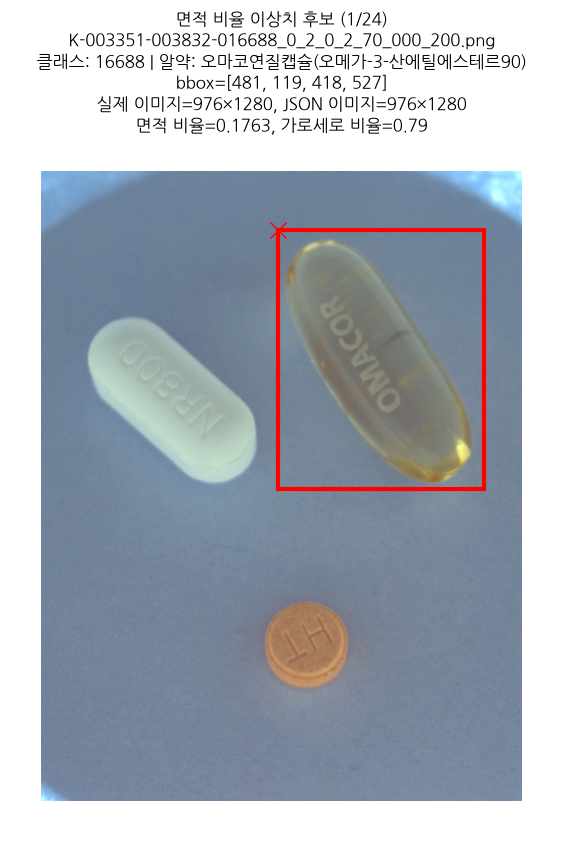

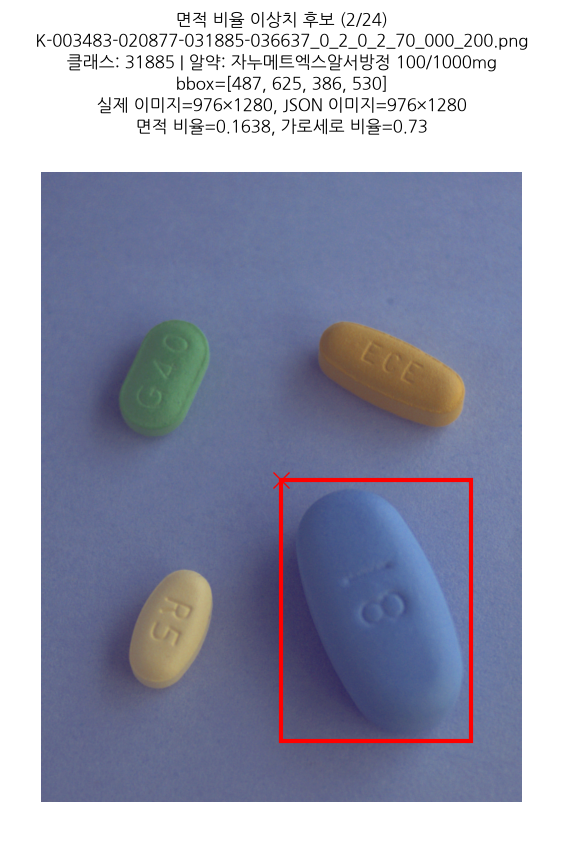

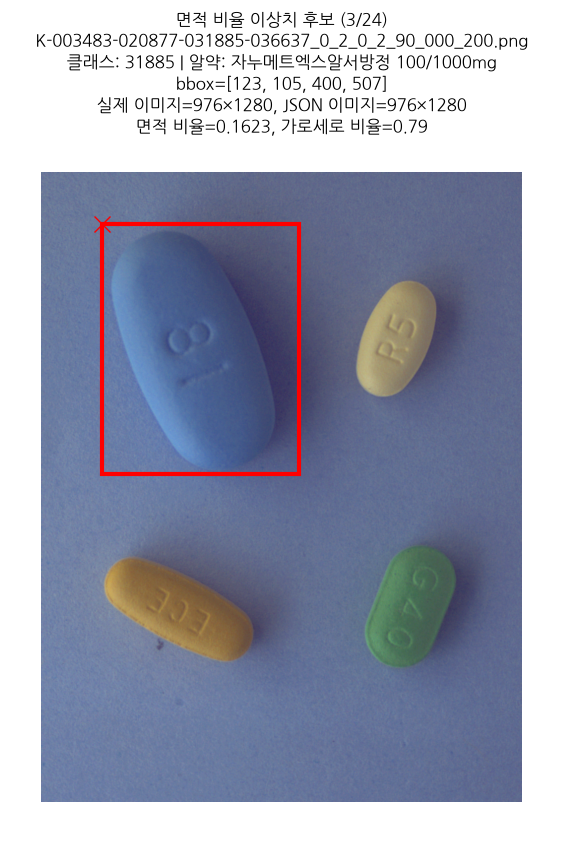

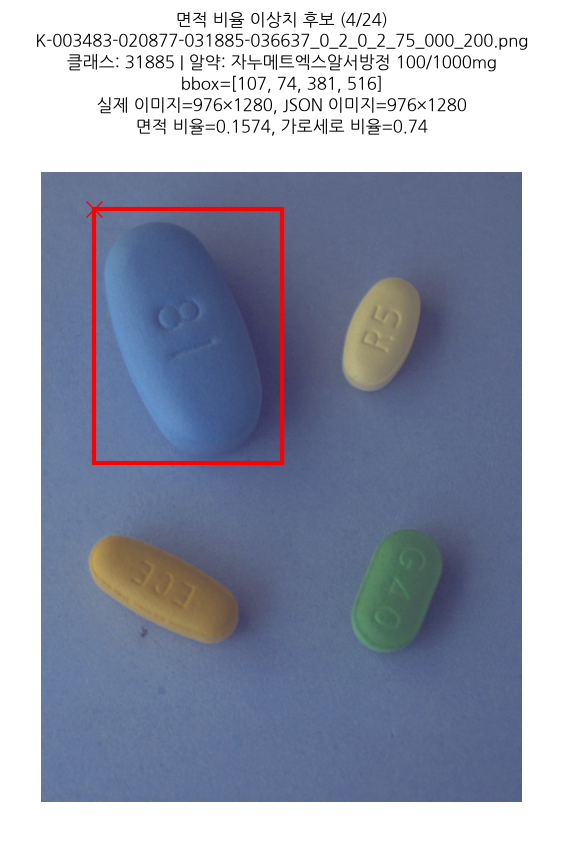

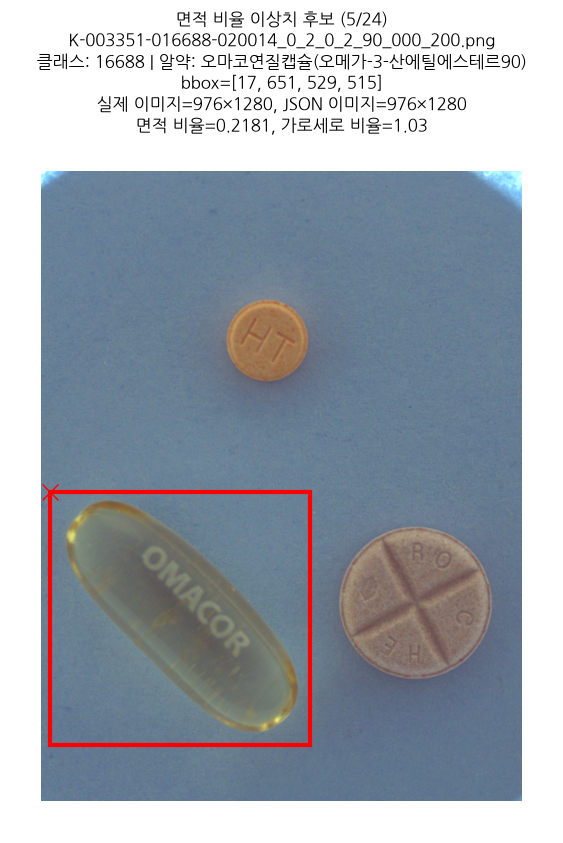

...

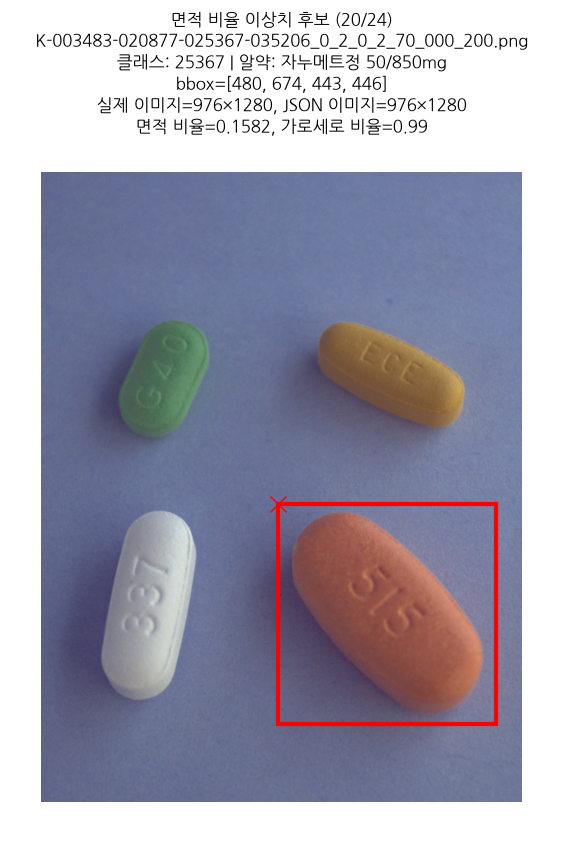

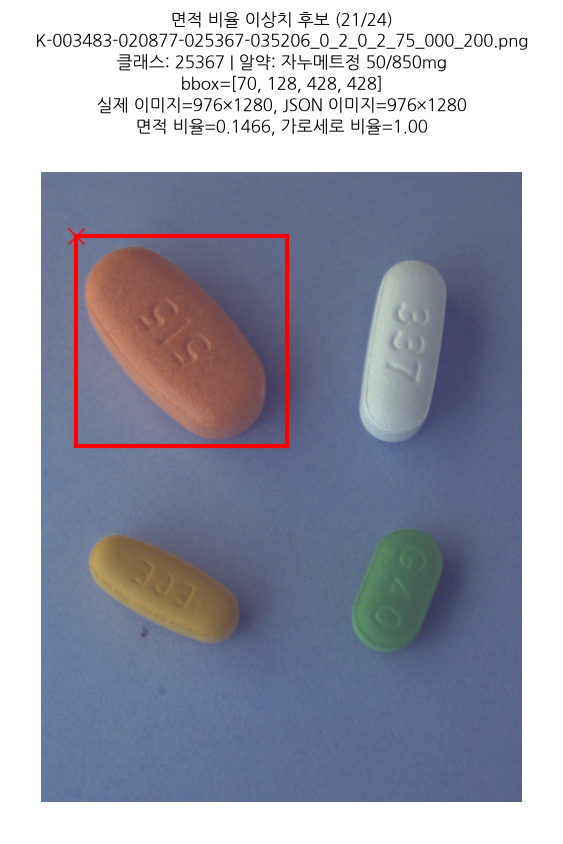

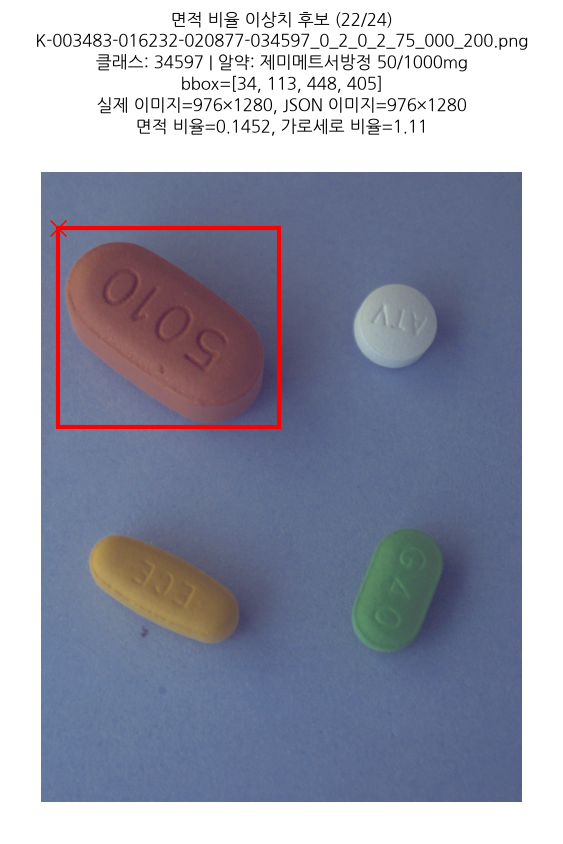

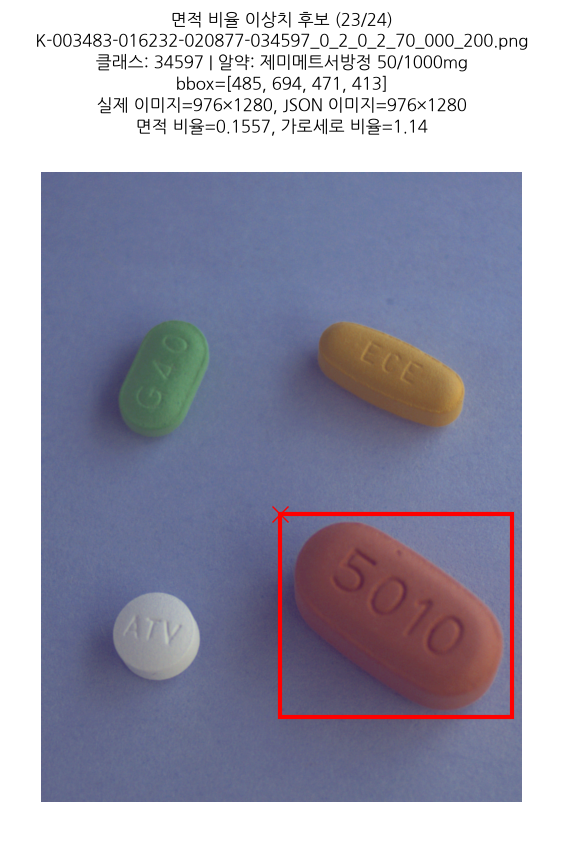

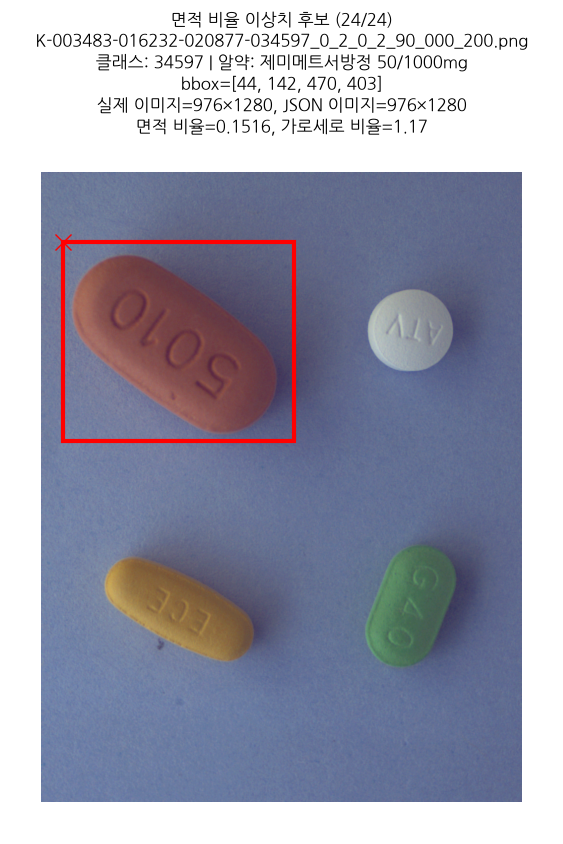

In [ ]:
area_outliers = valid_bbox_df.loc[valid_bbox_df["면적 비율 이상치 후보"]]

show_bbox_candidates(area_outliers, "면적 비율 이상치 후보")

In [ ]:
# 3. 유효한 박스 중 크기·비율이 특이한 것 찾기
valid_bbox_df = bbox_df.loc[~error_mask].copy()

# 이미지 전체 면적에서 bbox가 차지하는 비율
valid_bbox_df["면적 비율"] = (
    valid_bbox_df["width"]
    * valid_bbox_df["height"]
    / (valid_bbox_df["image_width"] * valid_bbox_df["image_height"])
)

# 박스의 가로 / 세로
valid_bbox_df["가로세로 비율"] = valid_bbox_df["width"] / valid_bbox_df["height"]

# IQR 기준으로 분포에서 멀리 떨어진 값 표시
for column in ["면적 비율", "가로세로 비율"]:
    q1 = valid_bbox_df[column].quantile(0.25)
    q3 = valid_bbox_df[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    valid_bbox_df[f"{column} 이상치 후보"] = (valid_bbox_df[column] < lower) | (
        valid_bbox_df[column] > upper
    )

candidate_columns = ["면적 비율 이상치 후보", "가로세로 비율 이상치 후보"]

outlier_df = valid_bbox_df.loc[valid_bbox_df[candidate_columns].any(axis=1)]

display(outlier_df)

,json_path,file_name,class_id,pill_name,image_width,image_height,x,y,width,height,크기 오류,이미지 크기 오류,이미지 밖,면적 비율,가로세로 비율,면적 비율 이상치 후보,가로세로 비율 이상치 후보
0,/home/edith/pill-bbox/data/raw/train_annotations/K-003351-021325-032310_json/K-032310/K-003351-021325-032310_0_2_0_2_75_000_200.json,K-003351-021325-032310_0_2_0_2_75_000_200.png,32310,글리아타민연질캡슐,976,1280,540,718,383,246,False,False,False,0.075418,1.556911,False,True
3,/home/edith/pill-bbox/data/raw/train_annotations/K-003351-021325-032310_json/K-021325/K-003351-021325-032310_0_2_0_2_75_000_200.json,K-003351-021325-032310_0_2_0_2_75_000_200.png,21325,아토르바정 10mg,976,1280,48,808,251,146,False,False,False,0.029334,1.719178,False,True
4,/home/edith/pill-bbox/data/raw/train_annotations/K-003351-021325-032310_json/K-021325/K-003351-021325-032310_0_2_0_2_90_000_200.json,K-003351-021325-032310_0_2_0_2_90_000_200.png,21325,아토르바정 10mg,976,1280,91,893,245,143,False,False,False,0.028044,1.713287,False,True
7,/home/edith/pill-bbox/data/raw/train_annotations/K-003351-003832-016688_json/K-016688/K-003351-003832-016688_0_2_0_2_70_000_200.json,K-003351-003832-016688_0_2_0_2_70_000_200.png,16688,오마코연질캡슐(오메가-3-산에틸에스테르90),976,1280,481,119,418,527,False,False,False,0.176330,0.793169,True,False
55,/home/edith/pill-bbox/data/raw/train_annotations/K-003483-020877-031885-036637_json/K-020877/K-003483-020877-031885-036637_0_2_0_2_70_000_200.json,K-003483-020877-031885-036637_0_2_0_2_70_000_200.png,20877,엑스포지정 5/160mg,976,1280,544,294,327,233,False,False,False,0.060988,1.403433,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
728,/home/edith/pill-bbox/data/raw/train_annotations/K-003483-016232-020877-034597_json/K-020877/K-003483-016232-020877-034597_0_2_0_2_70_000_200.json,K-003483-016232-020877-034597_0_2_0_2_70_000_200.png,20877,엑스포지정 5/160mg,976,1280,541,295,330,236,False,False,False,0.062340,1.398305,False,True
729,/home/edith/pill-bbox/data/raw/train_annotations/K-003483-016232-020877-034597_json/K-020877/K-003483-016232-020877-034597_0_2_0_2_90_000_200.json,K-003483-016232-020877-034597_0_2_0_2_90_000_200.png,20877,엑스포지정 5/160mg,976,1280,116,769,332,230,False,False,False,0.061123,1.443478,False,True
736,/home/edith/pill-bbox/data/raw/train_annotations/K-003483-016232-020877-034597_json/K-034597/K-003483-016232-020877-034597_0_2_0_2_75_000_200.json,K-003483-016232-020877-034597_0_2_0_2_75_000_200.png,34597,제미메트서방정 50/1000mg,976,1280,34,113,448,405,False,False,False,0.145236,1.106173,True,False
737,/home/edith/pill-bbox/data/raw/train_annotations/K-003483-016232-020877-034597_json/K-034597/K-003483-016232-020877-034597_0_2_0_2_70_000_200.json,K-003483-016232-020877-034597_0_2_0_2_70_000_200.png,34597,제미메트서방정 50/1000mg,976,1280,485,694,471,413,False,False,False,0.155708,1.140436,True,False


가로세로 비율 이상치 후보: 82개


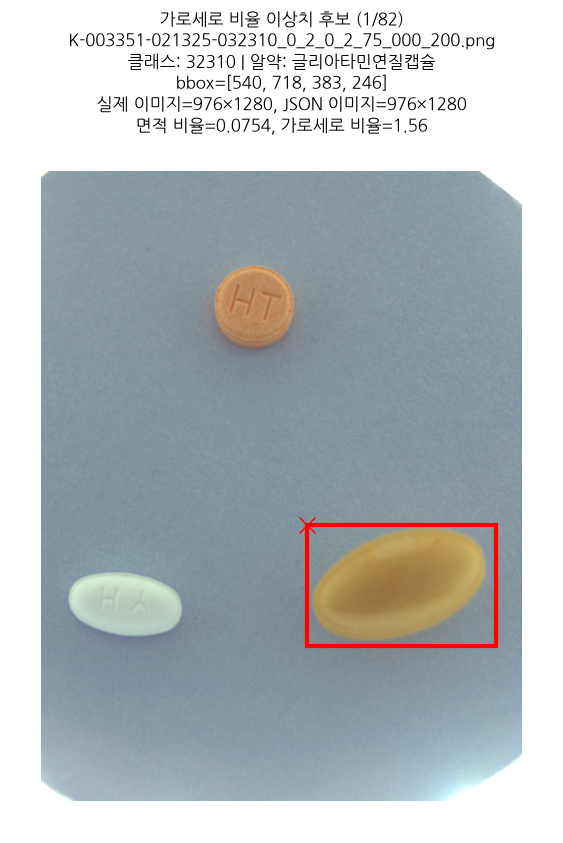

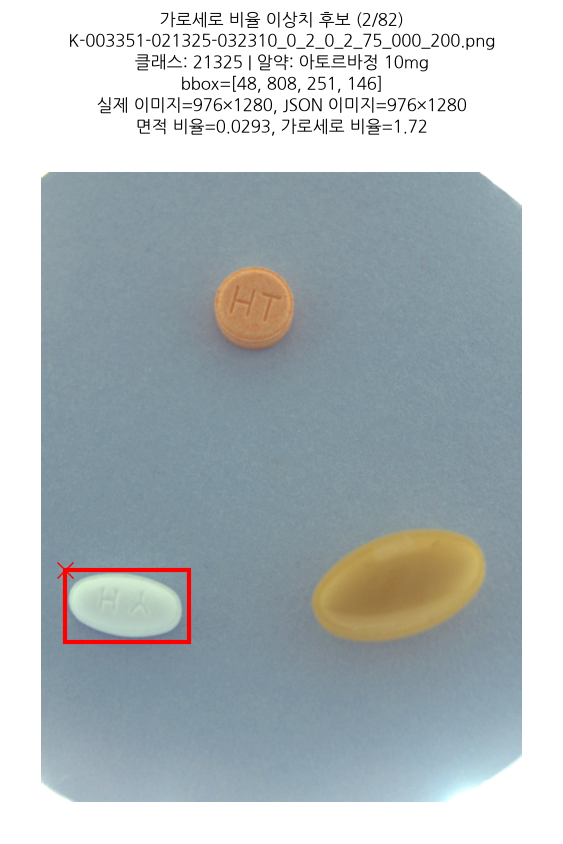

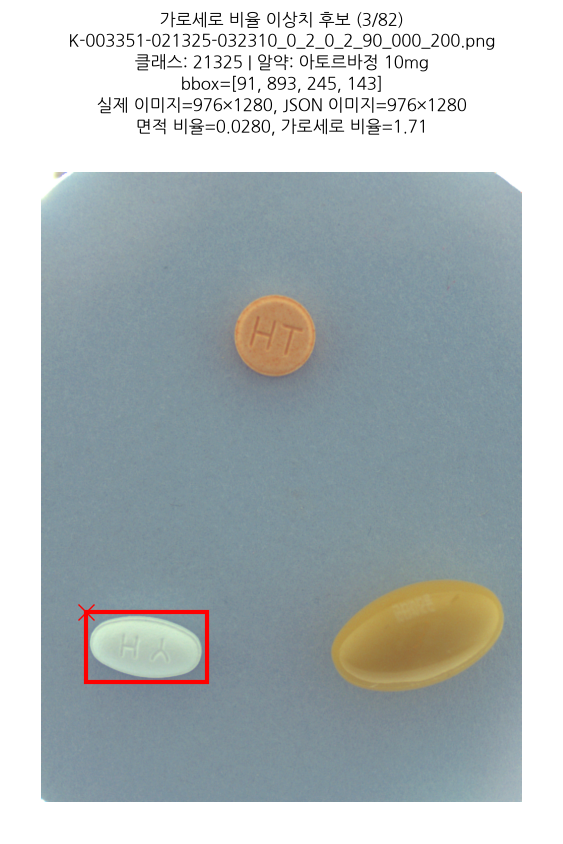

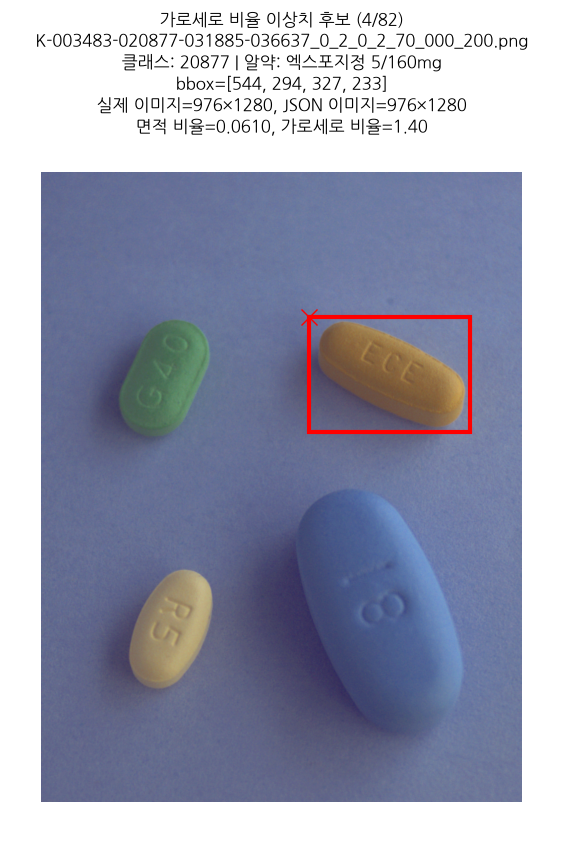

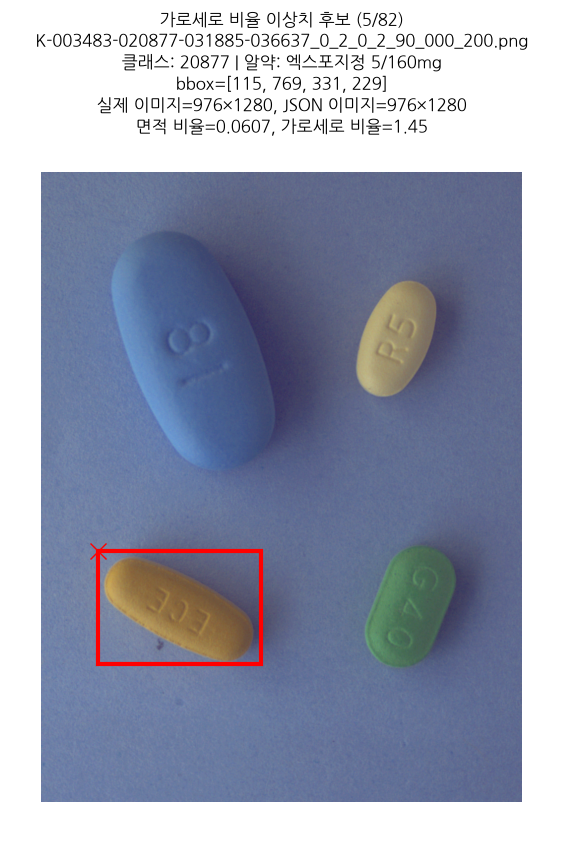

...

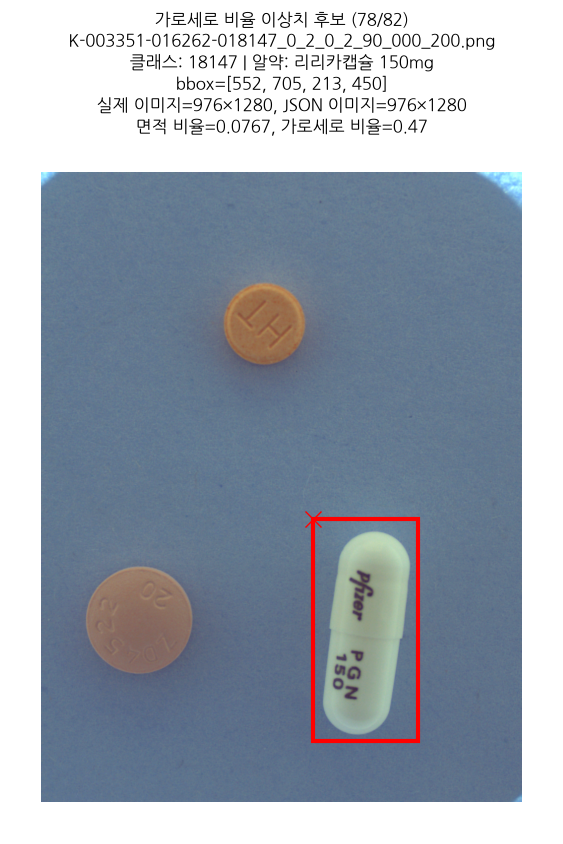

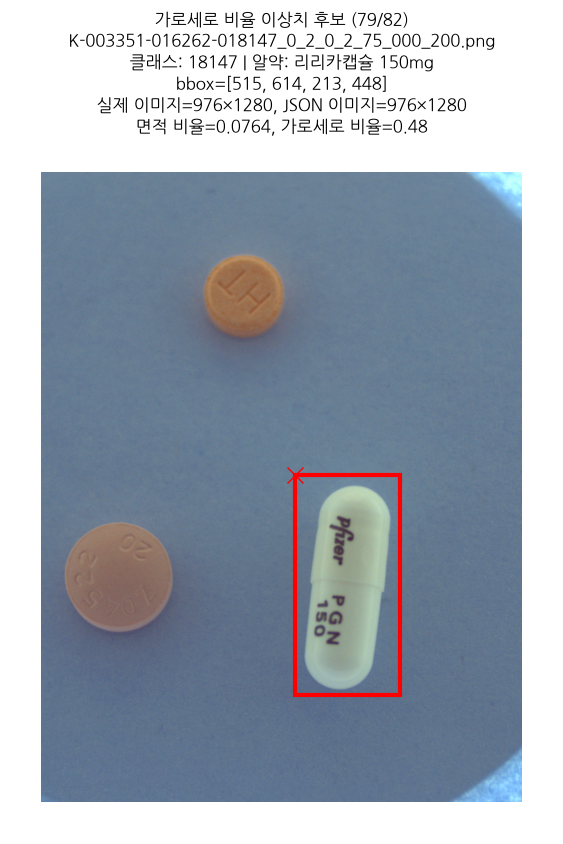

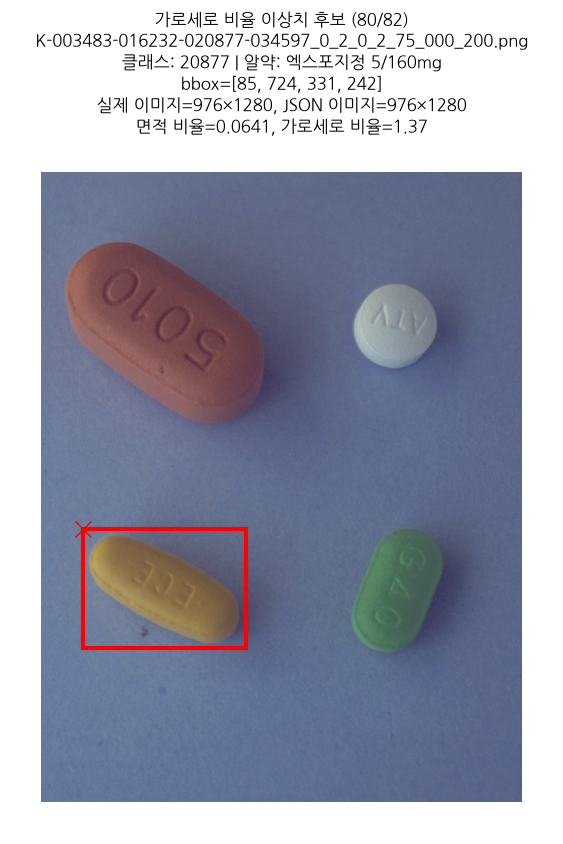

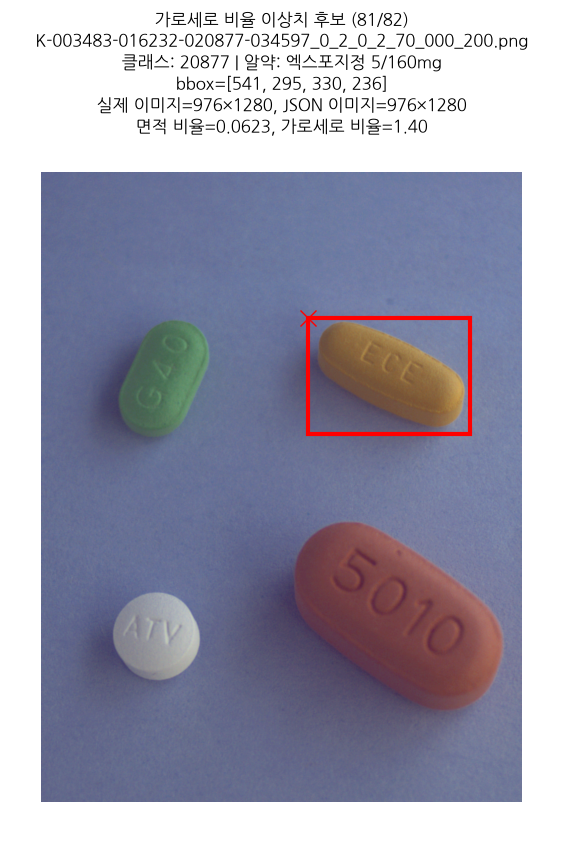

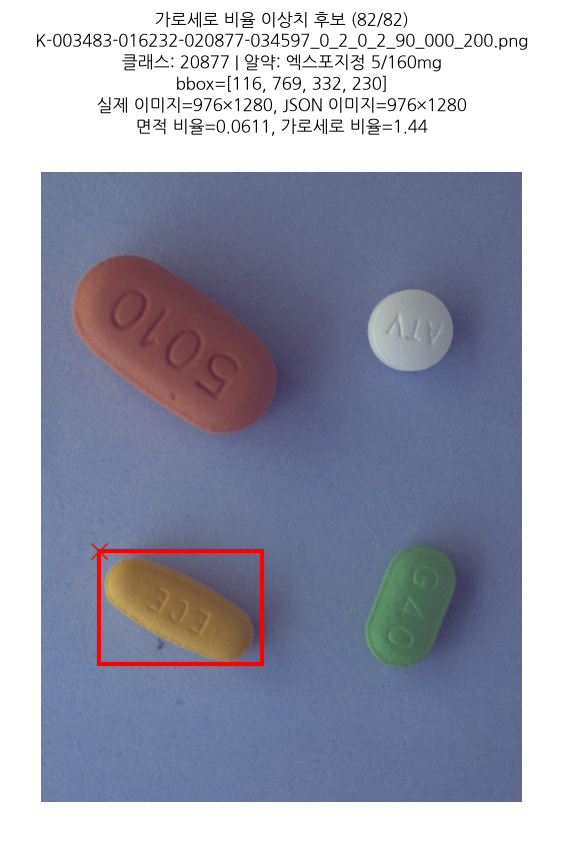

In [ ]:
ratio_outliers = valid_bbox_df.loc[valid_bbox_df["가로세로 비율 이상치 후보"]]

show_bbox_candidates(ratio_outliers, "가로세로 비율 이상치 후보")